# Part 1 — Frequent itemsets & association rules on Steam libraries

**Idea:** every player's library is a *shopping basket* and every game is an *item*.
If many players who own {Hades, Celeste} also own Hollow Knight, we get the rule
`{Hades, Celeste} -> Hollow Knight`, which we can use as a simple, *explainable* recommendation.

**Course topic:** frequent itemsets (A-Priori). Implemented from scratch below and checked against `mlxtend`.

Key terms:
* **support(I)** = fraction of baskets that contain every item in itemset I.
* **confidence(A -> b)** = support(A ∪ {b}) / support(A) = "of the players owning A, how many also own b".
* **lift(A -> b)** = confidence(A -> b) / support(b). Lift > 1 means owning A makes b *more* likely than for
  an average player. Confidence alone favours very popular games (everyone owns CS:GO), lift corrects for that.
* **interest(A -> b)** = confidence(A -> b) − support(b) (Week 5, slide 23). Close to 0 = not interesting,
  strongly positive = A encourages b. Lift is a *ratio*, interest is a *difference*: lift is highest for rare
  games (dividing by a small support), interest is highest when the confidence gain is large in absolute terms.

In [1]:
import ast, re, time, json, itertools, collections, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- configuration (every value here needs one sentence in the report) ----------------
DATA_FILE      = "australian_users_items.json"   # UCSD Steam data shared by Adam
OUT_DIR        = "outputs"                       # shared outputs (rules, train/test split)
BASKET_DEF     = "played"   # "played" = playtime_forever > 0 ; "owned" = everything in the library
MIN_SUPPORT    = 0.02       # an itemset must appear in >= 2% of baskets
MIN_CONFIDENCE = 0.20       # keep rules where >= 20% of antecedent-owners also own the consequent
MIN_LIFT       = 1.5        # keep rules that make the consequent at least 1.5x more likely
MAX_K          = 4          # largest itemset size we mine
TEST_FRAC      = 0.20       # fraction of users held out for evaluation (shared with the team)
VAL_FRAC       = 0.10       # fraction of *training* users held out to choose alpha (never the test users)
ALPHAS         = np.round(np.linspace(0, 1, 11), 1)   # alpha grid for score = conf^alpha * lift^(1-alpha)
SEED           = 42
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Load the data
The file looks like JSON but is actually one **Python dict per line** (single quotes), so `json.loads` fails.
We parse each line with `ast.literal_eval`. Game ID = Steam **appid** (`item_id`) as an `int`, the same key as the rest of the team.

In [2]:
t0 = time.time()
rows = []
with open(DATA_FILE) as fh:
    for line in fh:
        u = ast.literal_eval(line)
        for it in u["items"]:
            rows.append((u["user_id"], int(it["item_id"]), it["item_name"], it["playtime_forever"]))
df = pd.DataFrame(rows, columns=["user_id", "appid", "name", "playtime_forever"])
del rows
df = df.drop_duplicates(["user_id", "appid"])          # a few users appear twice in the raw file
names = df.drop_duplicates("appid").set_index("appid")["name"].to_dict()
print(f"loaded {len(df):,} (user, game) pairs, {df.user_id.nunique():,} users with >=1 game, "
      f"{df.appid.nunique():,} games in {time.time()-t0:.0f}s")

loaded 5,094,082 (user, game) pairs, 70,912 users with >=1 game, 10,978 games in 103s


## 2. Cleaning: remove non-game items
Steam libraries contain test clients, betas, SDKs and dedicated servers that are installed automatically
together with the real game. Example: *Left 4 Dead 2 Beta* is owned by **exactly** the same users as
*Left 4 Dead 2*, so A-Priori would find the useless rule `L4D2 Beta -> L4D2` with confidence 1.
*Dota 2 Test* is the most-owned item in the data but only ~7% of its owners ever played it.

In [3]:
NON_GAME = re.compile(r"\b(test server|test|beta|sdk|dedicated server|soundtrack|demo|public test)\b", re.I)
KEEP     = {"Test Drive Unlimited 2"}                    # real game that matches the regex
bad = {a for a, n in names.items() if NON_GAME.search(n) and n not in KEEP}
print(f"removing {len(bad)} non-game items, e.g.", [names[a] for a in list(bad)[:6]])
df = df[~df.appid.isin(bad)]

removing 74 non-game items, e.g. ['Crypt of the NecroDancer Extended Soundtrack', 'UNCORPOREAL - Holographic Photography Demo', 'Test Drive®: Ferrari Racing Legends', 'War of the Roses Balance Beta', 'Mad Max System Test', 'The Bellows: VR Demo']


### 2b. Merge "companion" entries into their main game
Some games are split into several Steam entries that you get together, e.g. *Call of Duty: Black Ops II*,
*… – Multiplayer* and *… – Zombies*. They produce rules like `CoD: Ghosts -> CoD: Ghosts – Multiplayer`
(lift 26, confidence 0.95), which are true but useless as recommendations and dominated the top-lift rules.
We **merge** them into the main game (one product = one item) instead of deleting them.
* **Automatic rule:** an entry whose name is *another game's name* + "Multiplayer" / "Zombies" / "Single Player".
  (A plain keyword search is too broad: it would also hit real games like *Plants vs. Zombies* or *Star Trek Online*.)
* **Manual list** for 4 cases that do not follow the naming pattern (each checked by hand, see comments).

In [4]:
norm = lambda s: re.sub(r"[™®]|\(tm\)", "", s, flags=re.I).strip().lower()
by_name = collections.defaultdict(list)
for a, n in names.items():
    by_name[norm(n)].append(a)
n_owners = df.appid.value_counts()

SUFFIX = re.compile(r"^(.*?)\s*[-:]?\s*(multiplayer|zombies|single ?player|singleplayer)$", re.I)
merge = {}
for a, n in names.items():
    m_ = SUFFIX.match(norm(n))
    if m_:
        parents = [p for p in by_name.get(m_.group(1).strip(), []) if p != a]
        if parents:
            merge[a] = max(parents, key=lambda p: n_owners.get(p, 0))   # most-owned entry with that name
MANUAL = {
    47830: 47790,    # Medal of Honor(TM) Multiplayer      -> Medal of Honor(TM) Single Player (same 6,036 owners)
    236830: 35450,   # Red Orchestra 2 - Single Player     -> Rising Storm/Red Orchestra 2 Multiplayer
    35420: 1250,     # Killing Floor Mod: Defence Alliance 2 -> Killing Floor (free for KF owners: 14,000 of 14,216)
    340: 220,        # Half-Life 2: Lost Coast (free tech demo bundled with HL2) -> Half-Life 2
}
merge.update(MANUAL)
names[47790] = "Medal of Honor (2010)"
names[35450] = "Red Orchestra 2 / Rising Storm"

print(f"merging {len(merge)} companion entries:")
for a, p in sorted(merge.items(), key=lambda x: -n_owners.get(x[0], 0)):
    print(f"   {names[a]:50s} -> {names[p]}")
df["appid"] = df.appid.map(lambda a: merge.get(a, a))
# one row per (user, game); playtime of merged entries is added up, so 'played' = played any part
df = df.groupby(["user_id", "appid"], as_index=False)["playtime_forever"].sum()

merging 15 companion entries:
   Half-Life 2: Lost Coast                            -> Half-Life 2
   Killing Floor Mod: Defence Alliance 2              -> Killing Floor
   Call of Duty: Black Ops II - Multiplayer           -> Call of Duty: Black Ops II
   Call of Duty: Black Ops II - Zombies               -> Call of Duty: Black Ops II
   Red Orchestra 2: Heroes of Stalingrad - Single Player -> Red Orchestra 2 / Rising Storm
   The Ship Single Player                             -> The Ship
   Medal of Honor(TM) Multiplayer                     -> Medal of Honor (2010)
   Call of Duty: Modern Warfare 2 - Multiplayer       -> Call of Duty: Modern Warfare 2
   Call of Duty: Black Ops - Multiplayer              -> Call of Duty: Black Ops
   Call of Duty: Modern Warfare 3 - Multiplayer       -> Call of Duty: Modern Warfare 3
   Call of Duty: Ghosts - Multiplayer                 -> Call of Duty: Ghosts
   Call of Duty: Advanced Warfare - Multiplayer       -> Call of Duty: Advanced Warfare
   

### 2c. Export the cleaned data for the team
Saved **before** the "played" filter, so every owned game is kept together with its playtime and each method
can choose its own basket definition (owned = all rows, played = `playtime_forever > 0`).
* `outputs/clean_baskets.parquet`: one row per (user_id, appid), columns `user_id, appid, name, playtime_forever`
* `outputs/cleaning_map.json`: which appids were removed and which were merged into which game

In [5]:
clean = df.assign(name=df.appid.map(names))[["user_id", "appid", "name", "playtime_forever"]]
clean.to_parquet(f"{OUT_DIR}/clean_baskets.parquet", index=False)
with open(f"{OUT_DIR}/cleaning_map.json", "w") as f:
    json.dump({
        "description": "Cleaning of australian_users_items.json (UCSD Steam). Game ID = Steam appid (int).",
        "removed_non_games": {str(a): names[a] for a in sorted(bad)},
        "merged_into": {str(a): {"name": names[a], "into": p, "into_name": names[p]}
                        for a, p in sorted(merge.items())},
        "renamed": {"47790": names[47790], "35450": names[35450]},
    }, f, indent=1, ensure_ascii=False)
print(f"saved {len(clean):,} rows ({clean.user_id.nunique():,} users, {clean.appid.nunique():,} games) "
      f"-> {OUT_DIR}/clean_baskets.parquet, {OUT_DIR}/cleaning_map.json")

saved 4,873,279 rows (69,029 users, 10,889 games) -> outputs/clean_baskets.parquet, outputs/cleaning_map.json


In [6]:
if BASKET_DEF == "played":
    df = df[df.playtime_forever > 0]
print(f"after cleaning ({BASKET_DEF}): {len(df):,} pairs, {df.user_id.nunique():,} users, {df.appid.nunique():,} games")

after cleaning (played): 3,189,913 pairs, 68,255 users, 9,986 games


## 3. Train / test split of *users*
The train test user split is saved to `outputs/split_users.json`  **we should evaluate on exactly the same users**.

In [7]:
users = np.array(sorted(df.user_id.unique()))
rng = np.random.default_rng(SEED)
test_users = set(rng.choice(users, size=int(TEST_FRAC * len(users)), replace=False))
with open(f"{OUT_DIR}/split_users.json", "w") as f:
    json.dump({"basket_def": BASKET_DEF, "seed": SEED,
               "test": sorted(test_users), "train": sorted(set(users) - test_users)}, f)

# Validation users: taken from the TRAINING users only, used to choose alpha in section 7.
# Rules are mined on the remaining training users, so neither validation nor test users are seen during mining.
train_all = [u for u in users if u not in test_users]
val_users = set(np.random.default_rng(SEED + 1).choice(train_all, size=int(VAL_FRAC * len(train_all)), replace=False))

baskets_all = df.groupby("user_id")["appid"].apply(frozenset)
train_baskets = [baskets_all[u] for u in train_all if u not in val_users]
N = len(train_baskets)
print(f"mining baskets: {N:,}   validation users: {len(val_users):,}   test users: {len(test_users):,}")

mining baskets: 49,144   validation users: 5,460   test users: 13,651


### Quick look at the data
Long tail: a few games are in a large share of libraries, most games are rare. This motivates (a) a support
threshold, and (b) ranking by **lift** rather than confidence.

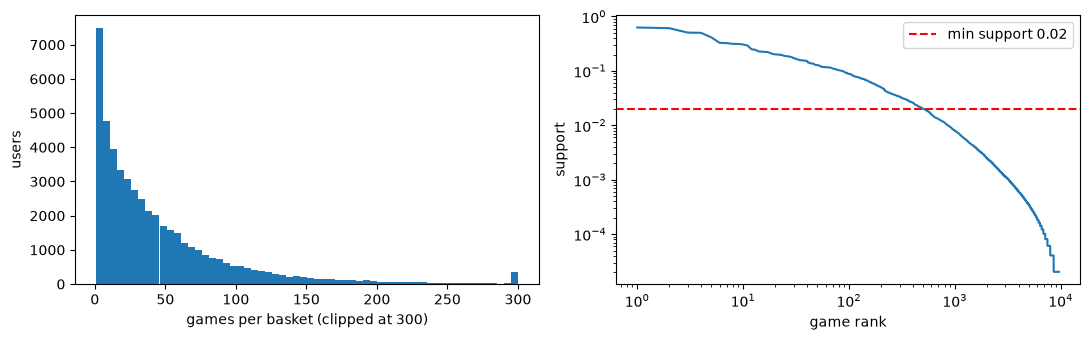

median basket size 29, mean 46.9, max 3459
most frequent games: [('Counter-Strike: Global Offensive', 0.628), ("Garry's Mod", 0.61), ('Left 4 Dead 2', 0.506), ('Unturned', 0.501), ('Terraria', 0.415)]


In [8]:
item_count = collections.Counter(a for b in train_baskets for a in b)
sizes = np.array([len(b) for b in train_baskets])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(np.clip(sizes, 0, 300), bins=60); ax[0].set_xlabel("games per basket (clipped at 300)"); ax[0].set_ylabel("users")
sup_sorted = np.array(sorted(item_count.values(), reverse=True)) / N
ax[1].loglog(np.arange(1, len(sup_sorted) + 1), sup_sorted)
ax[1].axhline(MIN_SUPPORT, ls="--", c="r", label=f"min support {MIN_SUPPORT}")
ax[1].set_xlabel("game rank"); ax[1].set_ylabel("support"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"median basket size {np.median(sizes):.0f}, mean {sizes.mean():.1f}, max {sizes.max()}")
print("most frequent games:", [(names[a], round(c / N, 3)) for a, c in item_count.most_common(5)])

## 4. A-Priori — our own implementation
A-Priori uses one simple fact: if a group of games is frequent, every smaller group inside it is also frequent. So it finds frequent single games first, then builds pairs only from those, then triples only from frequent pairs, and so on. This skips almost all the combinations it would otherwise have to count.
.

**Technical details**
* **Pass 1:** count every game and keep those with support ≥ `MIN_SUPPORT` → L1. Games are renumbered 0..m-1.
* **Pass 2:** count pairs of frequent games with the **triangular-matrix** method from the course
  (one counter per pair i<j stored in a 1-D array at index `i(2m-i-1)/2 + j-i-1`). This array
  needs m(m-1)/2 integers instead of a dict with tuple keys.
* **Triangular matrix vs. triples method:** the triangular matrix uses 1 integer for *every*
  possible pair, the triples method uses 3 integers `(i, j, count)` but only for pairs that occur in at least one
  basket. So triples only saves memory if **fewer than 1/3 of all possible pairs occur**. We measure this
  fraction on our data after pass 2 (printed below).
* **Pass k ≥ 3:** candidates C_k = join two frequent (k-1)-itemsets that share their first k-2 items, then
  **prune** any candidate with an infrequent (k-1)-subset. Counting uses one bit-vector per game
  (bit u = user u owns the game). The support of a candidate is `popcount(AND of its games' bit-vectors)`.
  Candidates that share the same prefix reuse the prefix's AND, so the work is vectorised in numpy.

In [9]:
POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.int64)   # popcount look-up table

def apriori_own(baskets, min_support, max_k=4, verbose=True):
    """Return dict {frozenset(appids): support} of all frequent itemsets up to size max_k."""
    n = len(baskets)
    minc = int(np.ceil(min_support * n))
    timings = {}

    # ---------- pass 1: single items ----------
    t = time.time()
    c1 = collections.Counter(a for b in baskets for a in b)
    L1 = sorted(a for a, c in c1.items() if c >= minc)
    idx = {a: i for i, a in enumerate(L1)}              # appid -> 0..m-1
    m = len(L1)
    freq = {frozenset([a]): c1[a] / n for a in L1}
    timings[1] = time.time() - t

    # ---------- pass 2: pairs with a triangular array ----------
    t = time.time()
    tri = np.zeros(m * (m - 1) // 2, dtype=np.int64)
    offset = lambda i, j: i * (2 * m - i - 1) // 2 + (j - i - 1)
    filtered = []                                        # baskets restricted to frequent items (reused later)
    for b in baskets:
        ii = np.array(sorted(idx[a] for a in b if a in idx), dtype=np.int64)
        filtered.append(ii)
        if len(ii) < 2:
            continue
        r, c = np.triu_indices(len(ii), 1)
        np.add.at(tri, offset(ii[r], ii[c]), 1)          # +1 for every pair in this basket
    # --- triangular matrix vs. triples method ---
    n_possible = m * (m - 1) // 2
    n_occurring = int((tri > 0).sum())                  # pairs that appear in at least one basket
    frac = n_occurring / n_possible
    apriori_own.pair_stats = {"possible pairs": n_possible, "occurring pairs": n_occurring,
                              "fraction occurring": frac,
                              "triangular MB": 4 * n_possible / 1e6, "triples MB": 12 * n_occurring / 1e6}
    if verbose:
        print(f"  pass 2: {n_occurring:,} of {n_possible:,} possible pairs occur ({frac:.1%}) -> "
              f"triangular {4*n_possible/1e6:.2f} MB vs triples {12*n_occurring/1e6:.2f} MB (4-byte ints); "
              f"use {'TRIPLES' if frac < 1/3 else 'TRIANGULAR'} (rule: triples only if < 1/3 occur)")
    I, J = np.triu_indices(m, 1)
    keep = tri >= minc
    Lk = [(int(i), int(j)) for i, j in zip(I[keep], J[keep])]   # frequent pairs as sorted index tuples
    for (i, j), c in zip(Lk, tri[keep]):
        freq[frozenset([L1[i], L1[j]])] = c / n
    timings[2] = time.time() - t

    # ---------- bit-vectors for passes k >= 3 ----------
    bits = np.zeros((m, n), dtype=bool)
    for u, ii in enumerate(filtered):
        bits[ii, u] = True
    bits = np.packbits(bits, axis=1)                     # m x ceil(n/8) bytes

    k = 3
    while Lk and k <= max_k:
        t = time.time()
        prev = set(Lk)
        # join step: group (k-1)-itemsets by their first k-2 items
        by_prefix = collections.defaultdict(list)
        for s in Lk:
            by_prefix[s[:-1]].append(s[-1])
        new_Lk, n_cand = [], 0
        for prefix, lasts in by_prefix.items():
            lasts.sort()
            for x, y in itertools.combinations(lasts, 2):
                cand = prefix + (x, y)
                # prune step: every (k-1)-subset must be frequent
                if all(cand[:p] + cand[p + 1:] in prev for p in range(k - 2)):
                    n_cand += 1
                    new_Lk.append(cand)
        # count all surviving candidates, grouped by their (k-1)-prefix
        counted = []
        groups = collections.defaultdict(list)
        for cand in new_Lk:
            groups[cand[:-1]].append(cand[-1])
        for prefix, lasts in groups.items():
            pv = np.bitwise_and.reduce(bits[list(prefix)], axis=0)        # AND of prefix games
            cnt = POPCOUNT[np.bitwise_and(bits[lasts], pv)].sum(axis=1)   # support of prefix + each last
            for last, c in zip(lasts, cnt):
                if c >= minc:
                    counted.append(prefix + (last,))
                    freq[frozenset(L1[i] for i in prefix + (last,))] = c / n
        Lk = sorted(counted)
        timings[k] = time.time() - t
        if verbose:
            print(f"  k={k}: {n_cand:,} candidates after pruning -> {len(Lk):,} frequent")
        k += 1

    if verbose:
        sizes = collections.Counter(len(s) for s in freq)
        print(f"  L1={m}, frequent itemsets by size: {dict(sorted(sizes.items()))}")
        print("  time per pass (s):", {k: round(v, 2) for k, v in timings.items()})
    return freq

t = time.time()
freq_own = apriori_own(train_baskets, MIN_SUPPORT, MAX_K)
time_own = time.time() - t
print(f"own A-Priori total: {time_own:.1f}s")

  pass 2: 127,260 of 127,260 possible pairs occur (100.0%) -> triangular 0.51 MB vs triples 1.53 MB (4-byte ints); use TRIANGULAR (rule: triples only if < 1/3 occur)


  k=3: 203,453 candidates after pruning -> 54,718 frequent


  k=4: 278,165 candidates after pruning -> 136,555 frequent
  L1=505, frequent itemsets by size: {1: 505, 2: 9741, 3: 54718, 4: 136555}
  time per pass (s): {1: 0.28, 2: 2.62, 3: 4.36, 4: 6.5}
own A-Priori total: 13.9s


## 5. Check against `mlxtend`
`mlxtend.apriori` needs a one-hot user × game table. A dense table of 57k users × 10k games is too big,
so we give it only the games that pass the 1-item support threshold (this is A-Priori's own first pass and
does not change the result). We check that both implementations return **the same itemsets with the same supports**.

In [10]:
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

L1_items = sorted(next(iter(s)) for s in freq_own if len(s) == 1)
col = {a: i for i, a in enumerate(L1_items)}
onehot = np.zeros((N, len(L1_items)), dtype=bool)
for u, b in enumerate(train_baskets):
    onehot[u, [col[a] for a in b if a in col]] = True
onehot = pd.DataFrame(onehot, columns=L1_items)

t = time.time()
freq_mlx = apriori(onehot, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_K, low_memory=True)
time_mlx = time.time() - t

mlx_dict = {frozenset(s): v for s, v in zip(freq_mlx.itemsets, freq_mlx.support)}
same_sets = set(mlx_dict) == set(freq_own)
max_diff = max(abs(mlx_dict[s] - freq_own[s]) for s in freq_own) if same_sets else None
print(f"own: {len(freq_own):,} itemsets in {time_own:.1f}s | mlxtend: {len(mlx_dict):,} itemsets in {time_mlx:.1f}s (+ one-hot)")
print("identical itemsets:", same_sets, "| max support difference:", max_diff)

own: 201,519 itemsets in 13.9s | mlxtend: 201,519 itemsets in 49.3s (+ one-hot)
identical itemsets: True | max support difference: 0.0


## 6. Association rules (own implementation) and the effect of lift
For every frequent itemset I with |I| ≥ 2 and every game b in I we form `I \ {b} -> b`.
We use **one game as consequent**: a recommendation is one game, and short rules are easy to explain.
All subsets of a frequent itemset are frequent, so every support we need is already in `freq_own`.

In [11]:
def make_rules(freq, min_conf, min_lift):
    out = []
    for I, sI in freq.items():
        if len(I) < 2:
            continue
        for b in I:
            A = I - {b}
            conf = sI / freq[A]
            sup_b = freq[frozenset([b])]
            lift = conf / sup_b                      # Week 5, slide 21
            interest = conf - sup_b                  # Week 5, slide 23
            if conf >= min_conf and lift >= min_lift:
                out.append((A, b, sI, conf, lift, interest))
    r = pd.DataFrame(out, columns=["antecedent", "consequent", "support", "confidence", "lift", "interest"])
    r["rule"] = [" + ".join(names[a] for a in sorted(A)) + "  ->  " + names[b]
                 for A, b in zip(r.antecedent, r.consequent)]
    return r

rules = make_rules(freq_own, MIN_CONFIDENCE, MIN_LIFT)
print(f"{len(rules):,} rules (conf >= {MIN_CONFIDENCE}, lift >= {MIN_LIFT})")

# sanity check against mlxtend's rule generator (single-consequent rules only)
r_mlx = association_rules(freq_mlx, metric="confidence", min_threshold=MIN_CONFIDENCE)
r_mlx = r_mlx[(r_mlx.consequents.apply(len) == 1) & (r_mlx.lift >= MIN_LIFT)]
print("mlxtend gives the same number of rules:", len(r_mlx) == len(rules))

pd.set_option("display.max_colwidth", 120)
print("\nTop 10 by CONFIDENCE (dominated by very popular consequents):")
COLS = ["rule", "support", "confidence", "lift", "interest"]
display(rules.sort_values("confidence", ascending=False).head(10)[COLS].round(3))
print("Top 10 by LIFT (more specific, 'taste' rules):")
display(rules.sort_values("lift", ascending=False).head(10)[COLS].round(3))
print("Top 10 by INTEREST (largest absolute gain in probability):")
display(rules.sort_values("interest", ascending=False).head(10)[COLS].round(3))

606,553 rules (conf >= 0.2, lift >= 1.5)


mlxtend gives the same number of rules: True

Top 10 by CONFIDENCE (dominated by very popular consequents):


,rule,support,confidence,lift,interest
545123,Arma 2 + Arma 3 + Arma 2: DayZ Mod -> Arma 2: Operation Arrowhead,0.039,0.997,5.035,0.799
206653,Counter-Strike: Source + Unturned + Double Action: Boogaloo -> Garry's Mod,0.023,0.995,1.630,0.384
545993,Arma 2 + Arma 2: DayZ Mod + Tom Clancy's Ghost Recon Phantoms - NA -> Arma 2: Operation Arrowhead,0.026,0.995,5.024,0.797
205481,Counter-Strike: Source + PAYDAY 2 + Toribash -> Garry's Mod,0.025,0.994,1.629,0.384
188050,Counter-Strike: Source + Portal 2 + Toribash -> Garry's Mod,0.024,0.994,1.629,0.384
502941,Garry's Mod + No More Room in Hell + BLOCKADE 3D -> Unturned,0.021,0.994,1.984,0.493
203599,Counter-Strike: Source + The Elder Scrolls V: Skyrim + Toribash -> Garry's Mod,0.022,0.994,1.628,0.383
545971,Arma 2 + Arma 2: DayZ Mod + Heroes & Generals -> Arma 2: Operation Arrowhead,0.047,0.993,5.016,0.795
203027,Counter-Strike: Source + Borderlands 2 + Toribash -> Garry's Mod,0.021,0.993,1.627,0.383
546030,Arma 2 + Arma 2: DayZ Mod + Dirty Bomb -> Arma 2: Operation Arrowhead,0.035,0.993,5.016,0.795


Top 10 by LIFT (more specific, 'taste' rules):


,rule,support,confidence,lift,interest
37,Half-Life: Opposing Force -> Half-Life: Blue Shift,0.020,0.725,27.374,0.699
36,Half-Life: Blue Shift -> Half-Life: Opposing Force,0.020,0.770,27.374,0.742
1550,"Warhammer 40,000: Dawn of War – Dark Crusade -> Warhammer 40,000: Dawn of War - Game of the Year Edition",0.020,0.715,17.802,0.675
1551,"Warhammer 40,000: Dawn of War - Game of the Year Edition -> Warhammer 40,000: Dawn of War – Dark Crusade",0.020,0.500,17.802,0.472
10092,Counter-Strike + Counter-Strike: Condition Zero -> Counter-Strike: Condition Zero Deleted Scenes,0.022,0.458,17.380,0.432
89395,"Warhammer® 40,000™: Dawn of War® II + Warhammer® 40,000™: Dawn of War® II – Retribution™ -> Warhammer® 40,000™: Da...",0.023,0.676,16.878,0.636
10090,Counter-Strike + Counter-Strike: Condition Zero Deleted Scenes -> Counter-Strike: Condition Zero,0.022,0.876,16.554,0.824
103,Counter-Strike: Condition Zero -> Counter-Strike: Condition Zero Deleted Scenes,0.022,0.424,16.087,0.398
102,Counter-Strike: Condition Zero Deleted Scenes -> Counter-Strike: Condition Zero,0.022,0.852,16.087,0.799
10889,Counter-Strike: Condition Zero + Counter-Strike: Global Offensive -> Counter-Strike: Condition Zero Deleted Scenes,0.021,0.422,16.017,0.396


Top 10 by INTEREST (largest absolute gain in probability):


,rule,support,confidence,lift,interest
10091,Counter-Strike: Condition Zero + Counter-Strike: Condition Zero Deleted Scenes -> Counter-Strike,0.022,0.958,10.884,0.870
423632,Counter-Strike: Global Offensive + Hitman: Sniper Challenge + PAYDAY 2 -> Hitman: Absolution,0.021,0.964,9.393,0.861
493499,Garry's Mod + Hitman: Sniper Challenge + PAYDAY 2 -> Hitman: Absolution,0.021,0.963,9.384,0.860
125957,Hitman: Sniper Challenge + PAYDAY 2 -> Hitman: Absolution,0.023,0.963,9.383,0.860
125959,Hitman: Sniper Challenge + Unturned -> Hitman: Absolution,0.021,0.962,9.375,0.859
49927,Portal 2 + Hitman: Sniper Challenge -> Hitman: Absolution,0.021,0.959,9.344,0.856
114173,The Elder Scrolls V: Skyrim + Hitman: Sniper Challenge -> Hitman: Absolution,0.022,0.958,9.336,0.855
259361,Left 4 Dead 2 + Counter-Strike: Global Offensive + Hitman: Sniper Challenge -> Hitman: Absolution,0.024,0.956,9.320,0.854
379595,Counter-Strike: Global Offensive + Garry's Mod + Hitman: Sniper Challenge -> Hitman: Absolution,0.025,0.956,9.316,0.853
274898,Left 4 Dead 2 + Garry's Mod + Hitman: Sniper Challenge -> Hitman: Absolution,0.023,0.956,9.314,0.853


In [12]:
# How popular are the recommended (consequent) games? Popularity = support of the consequent.
pop = {a: c / N for a, c in item_count.items()}
for metric in ["confidence", "lift", "interest"]:
    top = rules.sort_values(metric, ascending=False).head(200)
    print(f"top-200 rules by {metric:10s}: mean consequent support = {np.mean([pop[b] for b in top.consequent]):.3f}, "
          f"distinct consequents = {top.consequent.nunique()}")

# save rules with appids so the team can reuse them
rules_out = rules.assign(antecedent=rules.antecedent.apply(sorted)).sort_values("lift", ascending=False)
rules_out.to_csv(f"{OUT_DIR}/association_rules.csv", index=False)

top-200 rules by confidence: mean consequent support = 0.367, distinct consequents = 5
top-200 rules by lift      : mean consequent support = 0.062, distinct consequents = 21


top-200 rules by interest  : mean consequent support = 0.147, distinct consequents = 7


## 7. Rules as a recommender and evaluation
**Recommender:** for a user, a rule *fires* if the user owns every antecedent game and does not own the consequent.
Each candidate game gets the best score over all rules that fire for it. The rule that fired is the explanation
("recommended because you own X and Y").

**Evaluation protocol** (proposal for the whole team): for each user with ≥ 5 games, hide a random 20% of
their games, recommend 10 from the remaining 80%, and measure Precision@10, Recall@10 and NDCG@10 on the hidden games.
Baseline = the 10 most popular training games the user does not own. If a user triggers fewer than 10 rules,
the rest of the list is filled with popular games (we report how often that happens).
All methods see **the same hidden games for the same user**, so differences are not due to a different random split.

**Which score to rank by?** Confidence gives accurate but popular recommendations, lift gives varied but less
accurate ones. We try a blend:

$$\text{score}_\alpha = \text{conf}^{\alpha}\cdot\text{lift}^{1-\alpha} = \frac{\text{conf}}{\text{support}(b)^{\,1-\alpha}}$$

(because lift = conf / support(b)). So α is **one knob for how much we penalise popular games**: α = 1 is pure
confidence (no penalty), α = 0 is pure lift (full penalty). This is the same idea as Adam's IDF-weighted Jaccard.
Interest = conf − support(b) (Week 5, slide 23) is a different, *additive* penalty and is tested as its own option.

**No tuning on the test set:** α is chosen on the *validation* users (10% of training users, not used for mining).
The test users are evaluated only once, at the end, with the chosen α.

In [13]:
# ---------- vectorised rule matching (fast enough to evaluate many scores at once) ----------
pop = {a: c / N for a, c in item_count.items()}             # popularity = support in the mining baskets
popular_rank = [a for a, _ in item_count.most_common()]

# every game that appears in a rule, ordered by popularity -> ties in score are broken towards popular games
rule_games = sorted(set(rules.consequent) | {a for A in rules.antecedent for a in A}, key=lambda a: -pop[a])
pos = {a: i for i, a in enumerate(rule_games)}
M = len(rule_games); PAD = M                                 # extra slot that is always "owned" (pads short antecedents)

R = rules.assign(cpos=rules.consequent.map(pos)).sort_values("cpos", kind="stable").reset_index(drop=True)
ANT = np.full((len(R), R.antecedent.apply(len).max()), PAD)
for i, A in enumerate(R.antecedent):
    ANT[i, :len(A)] = [pos[a] for a in A]
CONS = R.cpos.to_numpy()
SEG = np.flatnonzero(np.r_[True, CONS[1:] != CONS[:-1]])    # start of each consequent's block of rules
SEG_ITEM = CONS[SEG]
CONF, LIFT, INTEREST = R.confidence.to_numpy(), R.lift.to_numpy(), R.interest.to_numpy()
SUPB = CONF / LIFT                                           # support of the consequent

def alpha_score(alpha):
    return CONF / SUPB ** (1 - alpha)                        # = conf^alpha * lift^(1-alpha)

def fired_rules(visible):
    owned = np.zeros(M + 1, dtype=bool); owned[PAD] = True
    owned[[pos[a] for a in visible if a in pos]] = True
    return owned[ANT].all(axis=1) & ~owned[CONS]             # antecedent owned, consequent not owned

def top_segments(fired, score, k):
    """Best score per consequent, then the k best consequents. Returns segment indices and masked scores."""
    masked = np.where(fired, score, -np.inf)
    best = np.maximum.reduceat(masked, SEG)
    ok = np.flatnonzero(np.isfinite(best))
    return ok[np.argsort(-best[ok], kind="stable")][:k], masked

def recommend_all(visible, schemes, k=10):
    """Top-k list for every scoring scheme (dict name -> score array) plus the popularity baseline."""
    fired = fired_rules(visible)
    fill = [a for a in popular_rank if a not in visible][:2 * k]
    out = {"most popular": (fill[:k], None)}
    for name, score in schemes.items():
        segs, _ = top_segments(fired, score, k)
        recs = [rule_games[SEG_ITEM[s]] for s in segs]
        n_rule = len(recs)
        recs += [a for a in fill if a not in recs][:k - n_rule]
        out[name] = (recs, n_rule)
    return out

def evaluate_all(user_pool, schemes, n_users=3000, k=10, seed=SEED):
    rng = np.random.default_rng(seed)
    pool = [u for u in sorted(user_pool) if len(baskets_all[u]) >= 5]
    pool = rng.choice(pool, size=min(n_users, len(pool)), replace=False)
    disc = 1 / np.log2(np.arange(2, k + 2))                  # NDCG discount for ranks 1..k
    st = collections.defaultdict(lambda: {"P": [], "R": [], "N": [], "fill": 0, "recs": collections.Counter()})
    for u in pool:
        games = np.array(sorted(baskets_all[u]))
        hidden = set(rng.choice(games, size=max(1, int(0.2 * len(games))), replace=False))
        visible = frozenset(games) - hidden
        idcg = disc[:min(k, len(hidden))].sum()
        for name, (recs, n_rule) in recommend_all(visible, schemes, k).items():
            hits = np.array([r in hidden for r in recs], dtype=float)
            s = st[name]
            s["P"].append(hits.sum() / k); s["R"].append(hits.sum() / len(hidden))
            s["N"].append((hits * disc[:len(hits)]).sum() / idcg)
            s["fill"] += n_rule is not None and n_rule < k
            s["recs"].update(recs)
    return pd.DataFrame({name: {
        "P@10": np.mean(s["P"]), "R@10": np.mean(s["R"]), "NDCG@10": np.mean(s["N"]),
        "coverage (distinct games)": len(s["recs"]),
        "mean popularity of recs": np.mean([pop.get(a, 0) for a in s["recs"].elements()]),
        "users needing popular fill": np.nan if name == "most popular" else s["fill"] / len(pool),
    } for name, s in st.items()}).T

### 7a. Choose α on the validation users

validation done in 65s


,P@10,R@10,NDCG@10,coverage (distinct games),mean popularity of recs,users needing popular fill
most popular,0.1320,0.1821,0.2191,37.0,0.3411,NaN
alpha=0.0,0.0719,0.1034,0.1112,220.0,0.0821,0.0007
alpha=0.1,0.0774,0.1108,0.1197,219.0,0.0900,0.0007
alpha=0.2,0.0848,0.1188,0.1310,217.0,0.1006,0.0007
alpha=0.3,0.0941,0.1320,0.1441,209.0,0.1146,0.0007
alpha=0.4,0.1015,0.1450,0.1575,193.0,0.1322,0.0007
alpha=0.5,0.1130,0.1631,0.1768,172.0,0.1569,0.0007
alpha=0.6,0.1315,0.1905,0.2045,146.0,0.1933,0.0007
alpha=0.7,0.1586,0.2220,0.2446,128.0,0.2439,0.0007
alpha=0.8,0.1736,0.2311,0.2746,115.0,0.2827,0.0007


best alpha on validation (max NDCG@10): 0.9


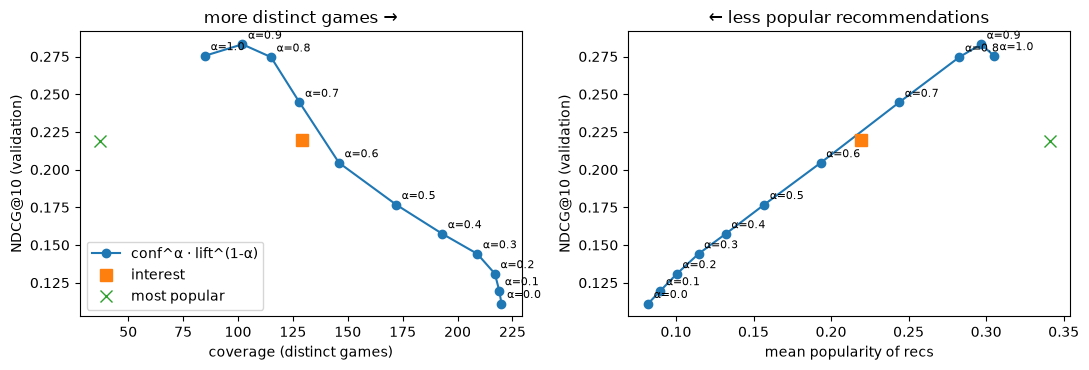

In [14]:
t = time.time()
val_schemes = {f"alpha={a}": alpha_score(a) for a in ALPHAS}
val_schemes["interest"] = INTEREST
val_res = evaluate_all(val_users, val_schemes, n_users=3000)
print(f"validation done in {time.time()-t:.0f}s")
display(val_res.round(4))

alpha_rows = val_res.loc[[f"alpha={a}" for a in ALPHAS]]
best_alpha = ALPHAS[int(np.argmax(alpha_rows["NDCG@10"].to_numpy()))]
print(f"best alpha on validation (max NDCG@10): {best_alpha}")

# trade-off plot: accuracy vs. variety / popularity, one point per alpha
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for j, xcol in enumerate(["coverage (distinct games)", "mean popularity of recs"]):
    ax[j].plot(alpha_rows[xcol], alpha_rows["NDCG@10"], "o-", label="conf^α · lift^(1-α)")
    for a, x, y in zip(ALPHAS, alpha_rows[xcol], alpha_rows["NDCG@10"]):
        ax[j].annotate(f"α={a}", (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
    for name, mk in [("interest", "s"), ("most popular", "x")]:
        ax[j].plot(val_res.loc[name, xcol], val_res.loc[name, "NDCG@10"], mk, ms=9, label=name)
    ax[j].set_xlabel(xcol); ax[j].set_ylabel("NDCG@10 (validation)")
ax[0].legend(); ax[0].set_title("more distinct games →"); ax[1].set_title("← less popular recommendations")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/alpha_tradeoff.png", dpi=150); plt.show()

### 7b. Final evaluation on the test users (run once)

In [15]:
test_schemes = {"rules, confidence (α=1)": alpha_score(1.0), "rules, lift (α=0)": alpha_score(0.0),
                "rules, interest": INTEREST}
if best_alpha not in (0.0, 1.0):
    test_schemes[f"rules, α={best_alpha} (chosen on validation)"] = alpha_score(best_alpha)
test_res = evaluate_all(test_users, test_schemes, n_users=3000)
display(test_res.round(4))
test_res.to_csv(f"{OUT_DIR}/rules_test_results.csv")

,P@10,R@10,NDCG@10,coverage (distinct games),mean popularity of recs,users needing popular fill
most popular,0.1279,0.1872,0.2162,41.0,0.3412,NaN
"rules, confidence (α=1)",0.1630,0.2280,0.2755,89.0,0.3061,0.001
"rules, lift (α=0)",0.0708,0.1058,0.1107,219.0,0.0825,0.001
"rules, interest",0.1394,0.1906,0.2215,130.0,0.2209,0.001
"rules, α=0.9 (chosen on validation)",0.1652,0.2309,0.2824,103.0,0.2982,0.001


In [16]:
# Example of an explainable recommendation for one test user (chosen alpha)
def explain(basket, score, k=10):
    fired = fired_rules(basket)
    segs, masked = top_segments(fired, score, k)
    for s in segs:
        lo, hi = SEG[s], (SEG[s + 1] if s + 1 < len(SEG) else len(CONS))
        j = lo + int(np.argmax(masked[lo:hi]))              # the rule that gave the best score
        print(f"  {names[rule_games[SEG_ITEM[s]]]:45s} because you own "
              + " + ".join(names[a] for a in sorted(R.antecedent[j])) + f"   (score {masked[j]:.2f})")

u = sorted(test_users)[7]
print("user owns:", [names[a] for a in list(baskets_all[u])[:15]], "...")
explain(baskets_all[u], alpha_score(best_alpha))

user owns: ["Garry's Mod", 'Killing Floor', 'PAYDAY 2', 'Left 4 Dead 2', 'H1Z1: Just Survive', 'Portal', 'Poker Night at the Inventory', 'The Binding of Isaac', 'The Binding of Isaac: Rebirth', 'Poker Night 2', 'Surgeon Simulator', 'Counter-Strike: Global Offensive', 'Half-Life 2'] ...
  Terraria                                      because you own The Binding of Isaac + PAYDAY 2 + The Binding of Isaac: Rebirth   (score 0.98)
  Portal 2                                      because you own Portal + The Binding of Isaac + Surgeon Simulator   (score 0.97)
  Unturned                                      because you own Garry's Mod + PAYDAY 2 + H1Z1: Just Survive   (score 0.87)
  Counter-Strike: Source                        because you own Half-Life 2 + Portal + Killing Floor   (score 0.86)
  The Elder Scrolls V: Skyrim                   because you own Half-Life 2 + The Binding of Isaac + PAYDAY 2   (score 0.85)
  Borderlands 2                                 because you own The Binding o